# Crisis dummies and recession bands: Portugal

In [1]:
# Setup: install the toolkit when running on Google Colab, and a plotting style
import sys

if "google.colab" in sys.modules:
    %pip install -q "econts[book] @ git+https://github.com/hmorao95/econ-time-series-manual"

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

A recession chronology is a 0/1 series: 1 in the quarters the economy was
in recession. It has two everyday uses: the **grey bands** behind a chart,
and **dummy variables** in a regression. This chapter does both with a
quarterly recession indicator for Portugal (1980–2020) and Portuguese GDP,
unemployment and the 10-year government bond yield.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import statsmodels.api as sm
import statsmodels.formula.api as smf
from econts import DATA_DIR, load

gdp = load("CLVMNACSCAB1GQPT").to_period("Q")  # real GDP, chained 2010 EUR mn
u = load("LRHUTTTTPTQ156S").to_period("Q")  # unemployment rate, %
y10 = load("IRLTLT01PTM156N").to_period("M")  # 10-year bond yield, %, monthly

## Reading the chronology

The file is tab-separated with day-first dates (`01/04/1980` is 1 April).
Parsed without a format, pandas reads it month-first, as 4 January:

In [3]:
raw = pd.read_csv(DATA_DIR / "pt_recessions.txt", sep="\t")
print(raw.head(3))
print(pd.to_datetime(raw["data"].head(3)).tolist())  # wrong: Jan 1, 4, 7

dates = pd.to_datetime(raw["data"], format="%d/%m/%Y")  # right
rec = pd.Series(
    raw["indicador"].to_numpy(), name="rec", index=pd.PeriodIndex(dates, freq="Q")
)
print(rec.index[[0, -1]], rec.sum(), "recession quarters")

         data  indicador
0  01/01/1980          0
1  01/04/1980          0
2  01/07/1980          0
[Timestamp('1980-01-01 00:00:00'), Timestamp('1980-01-04 00:00:00'), Timestamp('1980-01-07 00:00:00')]
PeriodIndex(['1980Q1', '2020Q4'], dtype='period[Q-DEC]', name='data') 30 recession quarters


## From dummy to episodes and back

A run of ones is one episode. Converting to a table of start and end dates
makes the chronology readable, and the reverse builds a dummy from a list of
dates (from a paper, a press release, a programme calendar).

In [4]:
def episodes(dummy: pd.Series) -> pd.DataFrame:
    """One row per run of ones: first quarter, last quarter, length."""
    d = dummy.fillna(0).astype(int)
    starts = d.index[(d == 1) & (d.shift(1, fill_value=0) == 0)]
    ends = d.index[(d == 1) & (d.shift(-1, fill_value=0) == 0)]
    return pd.DataFrame(
        {
            "start": starts,
            "end": ends,
            "length": [(e - s).n + 1 for s, e in zip(starts, ends)],
            "peak": starts - 1,  # last quarter before the fall
        }
    )


def dummy_from_episodes(index: pd.PeriodIndex, spans) -> pd.Series:
    """0/1 series on `index`, 1 inside each (start, end) span, inclusive."""
    out = pd.Series(0, index=index)
    for start, end in spans:
        out.loc[start:end] = 1
    return out


ep = episodes(rec)
ep["name"] = [
    f"{s.year}-{str(e.year)[2:]}" if e.year != s.year else str(s.year)
    for s, e in zip(ep["start"], ep["end"])
]
print(ep.to_string(index=False))

# The EU/IMF adjustment programme, May 2011 to May 2014
troika = dummy_from_episodes(rec.index.union(gdp.index), [("2011Q2", "2014Q2")])

 start    end  length   peak    name
1983Q2 1984Q1       4 1983Q1 1983-84
1992Q3 1993Q3       5 1992Q2 1992-93
2002Q2 2003Q2       5 2002Q1 2002-03
2008Q2 2009Q1       4 2008Q1 2008-09
2010Q4 2013Q1      10 2010Q3 2010-13
2020Q1 2020Q2       2 2019Q4    2020


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.dummies import episodes, dummy_from_episodes, episode_labels
```

## Grey bands

One helper for every chart. It converts each run of ones into a span from
the **start of its first period to the end of its last**, so the same
quarterly dummy shades a monthly or daily chart correctly.

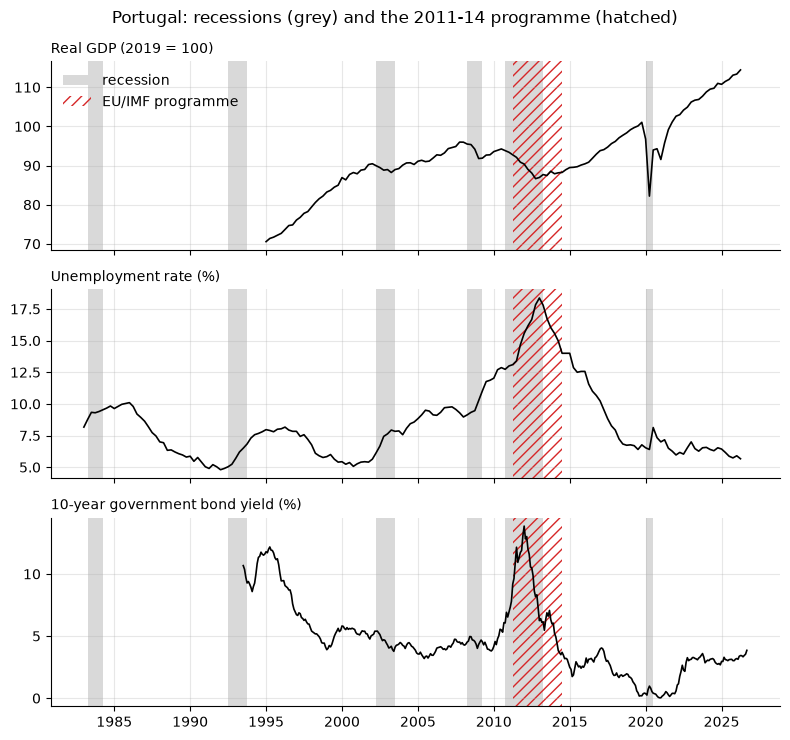

In [5]:
def shade(ax, dummy: pd.Series, **style) -> None:
    """Shade the periods where `dummy` == 1 (PeriodIndex or DatetimeIndex).

    `style` goes to `ax.axvspan`; the default is a plain grey band. For a
    hatched band pass e.g. fc="none", ec="C3", hatch="///".
    """
    if not {"color", "fc", "facecolor"} & style.keys():
        style["color"] = "0.85"
    style = {"lw": 0, "zorder": 0, **style}
    for _, row in episodes(dummy).iterrows():
        start, end = row["start"], row["end"]
        if isinstance(start, pd.Period):
            start, end = start.start_time, end.end_time
        ax.axvspan(start, end, **style)
        style.pop("label", None)  # label the first band only


fig, axes = plt.subplots(3, 1, figsize=(8, 7.5), sharex=True)
panels = [
    (100 * gdp / gdp["2019"].mean(), "Real GDP (2019 = 100)"),
    (u, "Unemployment rate (%)"),
    (y10, "10-year government bond yield (%)"),
]
for ax, (s, title) in zip(axes, panels):
    ax.plot(s.index.to_timestamp(), s.to_numpy(), color="k", lw=1.2)
    shade(ax, rec, label="recession")
    shade(ax, troika, fc="none", ec="C3", hatch="///", label="EU/IMF programme")
    ax.set_title(title, loc="left", fontsize=10)
axes[0].legend(loc="upper left")
fig.suptitle("Portugal: recessions (grey) and the 2011-14 programme (hatched)")
fig.tight_layout()

```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.dummies import shade
```

Variations: one color per crisis type, `alpha` for uncertainty (the last
section shades by probability), or `ax.axvline` at each peak and trough when
bands would hide the data.

## Recession dummies in regressions

The simplest use: average growth and unemployment change in recessions vs
expansions. Use HAC standard errors, since recession quarters cluster.

In [6]:
g = (100 * np.log(gdp).diff()).rename("g")  # q/q growth, %
du = u.diff().rename("du")  # change in unemployment, pp
df = pd.concat([g, du, rec], axis=1).dropna()  # 1995Q2-2020Q4, where all exist
print(df.groupby("rec")[["g", "du"]].mean().round(2))

m = smf.ols("du ~ rec", data=df).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(m.summary().tables[1])

        g    du
rec            
0.0  0.79 -0.11
1.0 -1.70  0.42
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.1142      0.071     -1.604      0.109      -0.254       0.025
rec            0.5301      0.142      3.739      0.000       0.252       0.808


`df` ends in 2020Q4 because the chronology does: `dropna` keeps only
quarters where the state is known. That is the correct treatment.

### Episode dummies

One dummy per crisis compares episodes. `pd.get_dummies` builds the matrix
from an episode label:

In [7]:
label = pd.Series(np.nan, index=rec.index, dtype=object)
for _, row in ep.iterrows():
    label.loc[row["start"] : row["end"]] = row["name"]
ep_dummies = pd.get_dummies(label, dtype=float).reindex(rec.index, fill_value=0.0)
print(ep_dummies.sum())  # quarters per episode

cum = pd.DataFrame(
    {
        "GDP change (log %)": g.groupby(label).sum(),
        "unemployment change (pp)": du.groupby(label).sum(),
        "quarters": label.value_counts(),
    }
)
print(cum.loc[ep["name"]].round(1))

1983-84     4.0
1992-93     5.0
2002-03     5.0
2008-09     4.0
2010-13    10.0
2020        2.0
dtype: float64
         GDP change (log %)  unemployment change (pp)  quarters
1983-84                 NaN                       1.2         4
1992-93                 NaN                       1.6         5
2002-03                -2.5                       2.3         5
2008-09                -4.5                       1.3         4
2010-13                -8.0                       5.5        10
2020                  -20.7                      -0.4         2


GDP starts in 1995, so the two earlier recessions show only the unemployment
response. The 2020 recession is the deepest in output and the only one in
which unemployment *fell*: job-retention schemes (*lay-off simplificado*)
and people leaving the labour force absorbed the shock.

### Slope dummies: does Okun's law change in recessions?

An interaction `g:rec` lets the slope differ between regimes. Estimated on
1995–2019, since 2020 breaks the link (see above):

In [8]:
okun = smf.ols("du ~ g * rec", data=df.loc[:"2019"]).fit(
    cov_type="HAC", cov_kwds={"maxlags": 4}
)
print(okun.params.round(3))
print(
    "slope in expansions:",
    okun.params["g"].round(3),
    "| in recessions:",
    (okun.params["g"] + okun.params["g:rec"]).round(3),
    "| p-value of the difference:",
    okun.pvalues["g:rec"].round(3),
)

Intercept   -0.121
g           -0.012
rec          0.389
g:rec       -0.256
dtype: float64
slope in expansions: -0.012 | in recessions: -0.267 | p-value of the difference: 0.027


In Portugal, Okun's law is a recession phenomenon: in expansions, faster
growth barely moves unemployment; in recessions, each point of lost growth
adds about a quarter point to the unemployment rate.

## Event study: crises side by side

Align each episode on its peak (the last quarter before the recession) and
plot the change from the peak. Leads and lags of the dummy are just the
quarters $t-4, \dots, t+12$ around each peak.

Text(0.5, 1.0, 'Portugal: unemployment rate around recession peaks')

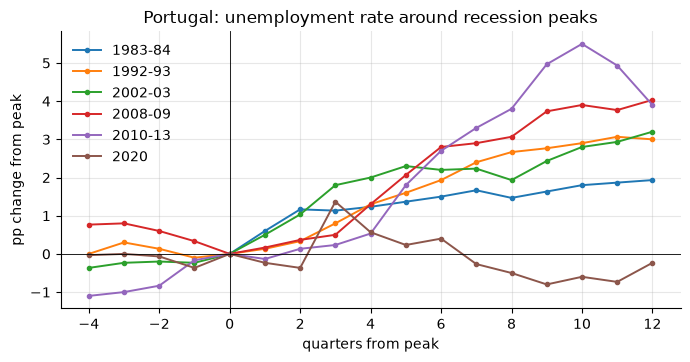

In [9]:
def around(s: pd.Series, peaks, before: int = 4, after: int = 12) -> pd.DataFrame:
    """Column per peak: s(t+k) - s(peak), for k = -before..after."""
    out = {}
    for p in peaks:
        k = range(-before, after + 1)
        out[p] = pd.Series(
            [s.get(p + j, np.nan) - s.get(p, np.nan) for j in k], index=list(k)
        )
    return pd.DataFrame(out)


paths = around(u, ep["peak"])
paths.columns = ep["name"].to_list()
ax = paths.plot(marker=".", lw=1.4)
ax.axvline(0, color="k", lw=0.6)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("quarters from peak")
ax.set_ylabel("pp change from peak")
ax.set_title("Portugal: unemployment rate around recession peaks")

The 2010–13 recession stands out: unemployment rose 5.5 pp in ten quarters,
twice as much as in any earlier episode. In 2020 it barely moved.

## Dummy types for outliers and breaks

| Type | Shape | Use for |
|---|---|---|
| pulse (additive outlier) | 0 0 1 0 0 | a one-quarter shock (strike, lockdown quarter) |
| step (level shift) | 0 0 1 1 1 | a permanent change in level (redefinition, euro entry) |
| ramp | 0 0 1 2 3 | a change in trend growth |
| temporary change | 0 0 1 .7 .49 | a shock that decays geometrically |

In [10]:
def pulse(index, at):
    return pd.Series((index == pd.Period(at, index.freq)).astype(float), index=index)


def step(index, at):
    return pd.Series((index >= pd.Period(at, index.freq)).astype(float), index=index)


def ramp(index, at):
    return step(index, at).cumsum()


def temporary_change(index, at, delta=0.7):
    s = step(index, at)
    return (delta ** (s.cumsum() - 1)).where(s == 1, 0.0)

```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.dummies import pulse, step, ramp, temporary_change
```

Two pulse dummies for the 2020 lockdown and reopening transform an AR(1) for
Portuguese GDP growth:

In [11]:
gg = g.dropna()
covid = pd.concat(
    {"2020Q2": pulse(gg.index, "2020Q2"), "2020Q3": pulse(gg.index, "2020Q3")}, axis=1
)
fits = {
    "no dummies": sm.tsa.SARIMAX(gg, order=(1, 0, 0), trend="c").fit(disp=False),
    "COVID pulses": sm.tsa.SARIMAX(gg, exog=covid, order=(1, 0, 0), trend="c").fit(
        disp=False
    ),
}
print(pd.DataFrame({k: r.params for k, r in fits.items()}).round(3))

           no dummies  COVID pulses
2020Q2            NaN       -15.540
2020Q3            NaN        13.275
ar.L1          -0.192         0.247
intercept       0.459         0.308
sigma2          4.459         0.995


Without the dummies, the two 2020 observations dominate: persistence turns
negative (a crash followed by a rebound looks like mean reversion) and the
residual variance is four times larger.

## Recession probabilities as bands

Hamilton's (1989) Markov-switching model lets GDP growth switch between a
high-mean and a low-mean regime and estimates the probability of being in
the low one each quarter. Shading with that probability as the opacity
compares a model-based chronology with the official one. Estimated on
1995–2019, to keep 2020 from becoming a regime of its own:

In [12]:
y_ms = gg.loc[:"2019"].to_timestamp().asfreq("QS")
ms = sm.tsa.MarkovRegression(y_ms, k_regimes=2).fit(disp=False, search_reps=20)
low = int(np.argmin([ms.params["const[0]"], ms.params["const[1]"]]))
prob = ms.smoothed_marginal_probabilities[low]
prob.index = prob.index.to_period("Q")
print(ms.params.round(3))

both = pd.concat([prob.rename("p"), rec], axis=1).dropna()
concordance = ((both["p"] > 0.5).astype(int) == both["rec"]).mean()
print(f"concordance with the official dating: {concordance:.2f}")

p[0->0]     0.800
p[1->0]     0.042
const[0]   -0.813
const[1]    0.631
sigma2      0.326
dtype: float64
concordance with the official dating: 0.99


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.cycles import concordance
```

The concordance index (Harding and Pagan, 2002) is the share of quarters in
which the two chronologies agree.

Text(0.5, 1.0, 'Portugal: GDP growth (%, q/q) and recession probability')

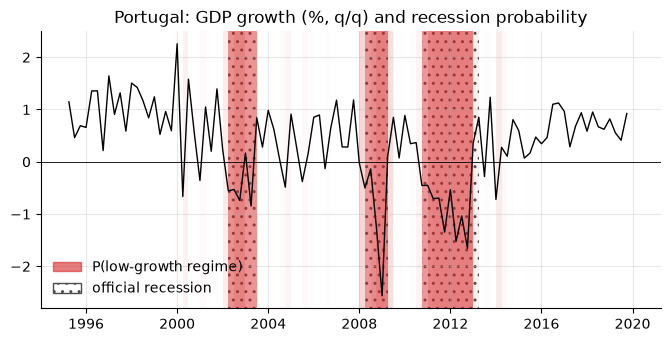

In [13]:
fig, ax = plt.subplots()
for q, p in prob.items():  # one band per quarter, opacity = p
    ax.axvspan(q.start_time, q.end_time, color="C3", alpha=0.6 * p, lw=0)
growth = gg.loc[:"2019"]
ax.plot(growth.index.to_timestamp(), growth.to_numpy(), color="k", lw=1)
shade(ax, rec.loc["1995":"2019"], fc="none", ec="0.3", hatch="..")
ax.axhline(0, color="k", lw=0.6)
ax.legend(
    handles=[
        Patch(color="C3", alpha=0.6, label="P(low-growth regime)"),
        Patch(fc="none", hatch="..", ec="0.3", label="official recession"),
    ],
    loc="lower left",
)
ax.set_title("Portugal: GDP growth (%, q/q) and recession probability")

## Pitfalls

* **Chronologies end.** This one stops in 2020Q4. Reindexing to a longer
  sample creates `NaN` after that date; keep them, or extend the chronology
  explicitly.
* **The dummy trap.** A constant plus a recession dummy plus an expansion
  dummy is perfectly collinear. Use one of the two.
* **Timing conventions differ.** Some chronologies mark the peak quarter as
  the first recession quarter, others mark the quarter after it. Check before
  merging two sources or computing durations.
* **Monthly charts, quarterly dummies.** Do not `asfreq` the dummy to monthly
  with `ffill` and then shade month by month: use period start and end times,
  as `shade` does.

## Summary

* Shade the **whole period**: a band for 2008Q2 runs from 1 April to
  30 June, not from one tick mark to the next.
* Beyond the end of the chronology the state is **unknown**, not
  "expansion". Keep it `NaN`; never `fillna(0)` blindly.
* Choose the dummy type to match the event: **pulse** for a one-off,
  **step** for a permanent shift, a **slope dummy** (interaction) when the
  relationship itself changes in recessions.
* Do not regress GDP on a recession dummy built from GDP and call it a
  finding: the dummy is defined by the outcome.

## Exercises

1. Read the Portuguese chronology and build the episodes table. What share of the quarters from 1980 to 2020 were in recession, and what is the average episode length? Reindex the indicator to 1980Q1–2026Q2 and check that the quarters after 2020Q4 are `NaN`.
2. Average the Portuguese 10-year yield (`IRLTLT01PTM156N`) to quarters and, for each recession episode from 1995 on, compute the rise from the peak quarter to the highest yield within the episode. Which episode stands out, and why was that recession different from the others?
3. Use `around` to plot log Portuguese real GDP × 100 (`CLVMNACSCAB1GQPT`) relative to each recession peak since 1995, from 4 quarters before to 12 after. Which episode is deepest after four quarters, and which recovers its pre-recession level fastest?
4. Estimate the two-regime Markov-switching model on US quarterly GDP growth (`GDPC1`, 1960–2019) and compute its concordance with `USRECQ`. Then allow the variance to switch (`switching_variance=True`): which version matches the NBER dating better, and why might a switching variance help or hurt?